# Lesson 3: teaching a model to paint parking regions

Imagine tracing the parking spaces on a photograph with a highlighter. **Segmentation** asks the model to paint that region. This is different from finding a car, deciding if one space is occupied, or predicting availability later.

This workbook replays a saved, genuinely trained **development candidate**. It does not retrain a model, download anything or open the newly reserved final images. Run the cells in order using Python (Smart Parking).

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src/smart_parking').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/smart_parking').is_dir(), 'Open this notebook from the project workspace'
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
RUN = ROOT / 'experiments/results/REGION-TRANSFER-20261024T204533261212Z'
report = json.loads((RUN / 'run.json').read_text())
print('Project:', ROOT)
print('Real source:', report['source_id'])
print('Use: known-camera development comparison; no final accuracy claim')

Project: D:\deep learning\project001
Real source: SRC-DS-001
Use: known-camera development comparison; no final accuracy claim


## 1. Borrowing trained eyesight

ResNet18 has upstream ImageNet weights. We freeze its visual features, including its batch-normalization statistics. Our project trains a new decoder to turn those features into a parking-region mask. The decoder also sees the picture's row/column coordinates and RGB pixels.

Think of an experienced observer describing what they see while a new assistant learns where to put the highlighter. Only the assistant's learned numbers change. Absolute coordinates can specialize to a view; this is **not evidence of generalization to a new camera**.

In [2]:
print('Seed:', report['seed'])
print('Training/validation frames: 36 / 6')
print('Epochs:', report['epochs_completed'], '| selected epoch:', report['best_epoch'])
print('Measured duration:', round(report['duration_seconds'], 2), 'seconds on CPU')
print('Validation gate passed:', report['validation_gate_passed'])
print('New final images decoded:', report['final_images_decoded'])
assert report['final_images_decoded'] == 0
print('Production changed:', report['production_changed'])

Seed: 71
Training/validation frames: 36 / 6
Epochs: 80 | selected epoch: 79
Measured duration: 129.57 seconds on CPU
Validation gate passed: False
New final images decoded: 0
Production changed: False


## 2. Restore the saved candidate

We read the original local pretrained weights and the separately saved project decoder. Their recorded fingerprints identify the exact files. We select **only validation rows before opening images or annotations**. The final reservation stays closed because the candidate failed its validation gate.

In [3]:
import torch
import numpy as np
from PIL import Image
from torchvision.models import resnet18
from smart_parking.region_transfer import FrozenRegionEncoder, RegionDecoder
from smart_parking.provenance import digest
from train_region_transfer import load, metric

torch.set_num_threads(4)
weights = ROOT / 'models/pretrained/resnet18_imagenet.pth'
assert digest(weights) == report['encoder_weights_sha256']
assert digest(RUN / 'candidate.pt') == report['checkpoint_sha256']
backbone = resnet18(weights=None)
backbone.load_state_dict(torch.load(weights, map_location='cpu', weights_only=True))
encoder = FrozenRegionEncoder(backbone)
decoder = RegionDecoder()
decoder.load_state_dict(torch.load(RUN / 'candidate.pt', map_location='cpu', weights_only=True)['decoder_state_dict'])
decoder.eval()
manifest = json.loads((ROOT / 'data/manifests/segmentation_known_camera_v1.json').read_text())
validation = [row for row in manifest['frames'] if row['split'] == 'validation']
assert len(validation) == 6
rgb, truth = load(validation)
mean = torch.tensor([.485, .456, .406])[None, :, None, None]
std = torch.tensor([.229, .224, .225])[None, :, None, None]
with torch.no_grad():
    predicted = (decoder(rgb, encoder((rgb - mean) / std)).sigmoid() >= .5).numpy()
print('All encoder parameters frozen:', all(not p.requires_grad for p in encoder.parameters()))
print('Output dimensions:', predicted.shape, '(images, channels, rows, columns)')

All encoder parameters frozen: True
Output dimensions: (6, 1, 112, 192) (images, channels, rows, columns)


## 3. Check the result instead of trusting a label

IoU is the intersection of predicted and labelled foreground divided by their union. It is **not** the percentage of correctly classified occupied spaces.

The previous tiny candidate uses its original image-resizing pipeline; the transfer candidate uses its preregistered pipeline. The six images and nearest-neighbour truth masks match, but capacity, pretraining and augmentation differ. This comparison does not isolate which individual change caused a gain.

In [4]:
actual = (truth >= .5).numpy()
saved = np.stack([np.asarray(Image.open(RUN / f'validation_candidate_{i}.png')) > 127 for i in range(6)])[:, None]
assert np.array_equal(predicted, saved), 'Replayed masks differ from the selected checkpoint'
measured = metric(predicted, actual)
assert abs(measured['pixel_iou'] - report['validation']['overall']['pixel_iou']) < 1e-12
comparison = json.loads((RUN / 'matched_validation_comparators.json').read_text())
print('Replayed candidate IoU:', round(measured['pixel_iou'], 4))
for name, value in comparison['models'].items():
    print('Saved comparison:', name, round(value['metrics']['overall']['pixel_iou'], 4))
print('Train-only fixed-map baseline:', round(report['validation_geometry']['overall']['pixel_iou'], 4))
for camera, value in report['validation']['per_camera'].items():
    print(camera, 'candidate IoU', round(value['pixel_iou'], 4))
print('Conclusion: useful development gain; failed quality gate, final set closed, app unchanged.')

Replayed candidate IoU: 0.7705
Saved comparison: production_tiny_unet 0.253
Saved comparison: known_camera_tiny_unet 0.4665
Train-only fixed-map baseline: 0.7676
pucpr candidate IoU 0.8516
ufpr04 candidate IoU 0.6581
ufpr05 candidate IoU 0.7603
Conclusion: useful development gain; failed quality gate, final set closed, app unchanged.


## 4. Read the pictures

White means predicted/labelled parking region. Our candidate still merges some spaces into broad bands. It does not produce verified individual slot IDs. A reliable fixed map remains a strong baseline when the camera view is unchanged.

**Attribution:** original PKLot photographs and slot annotations, Almeida et al., UFPR, CC BY 4.0. The combined presentation and model masks are modified material; original source files stay unchanged. See the project source and licence records.

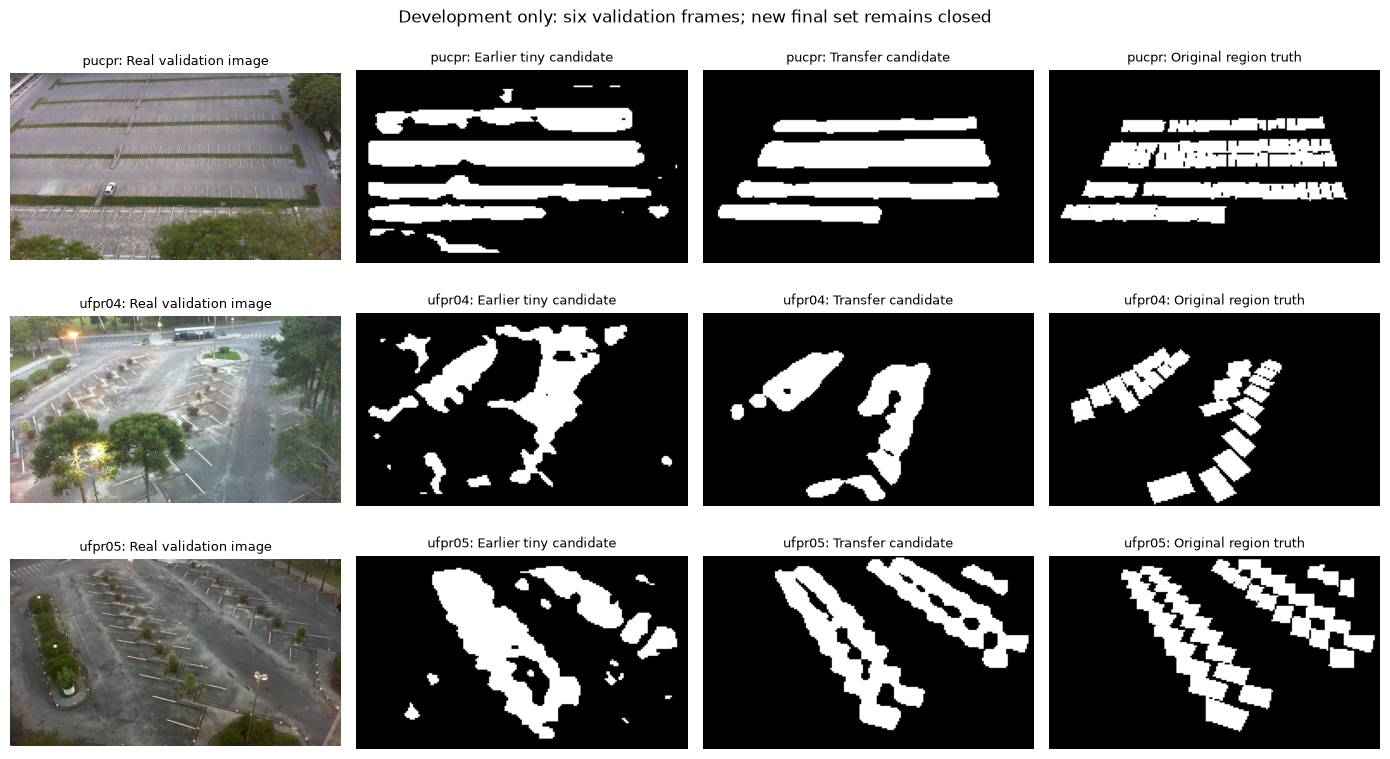

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for j, camera in enumerate(['pucpr', 'ufpr04', 'ufpr05']):
    i = next(i for i, row in enumerate(validation) if row['camera_id'] == camera)
    views = [(ROOT / validation[i]['image'], 'Real validation image'),
             (RUN / f'known_camera_tiny_unet_{i}.png', 'Earlier tiny candidate'),
             (RUN / f'validation_candidate_{i}.png', 'Transfer candidate'),
             (RUN / f'validation_truth_{i}.png', 'Original region truth')]
    for ax, (path, title) in zip(axes[j], views):
        image = Image.open(path)
        ax.imshow(image, cmap='gray' if image.mode == 'L' else None)
        ax.set_title(camera + ': ' + title, fontsize=9)
        ax.axis('off')
fig.suptitle('Development only: six validation frames; new final set remains closed')
plt.tight_layout()
plt.show()

## 5. A live score needs coverage too

If no matching later observation arrives inside a forecast's allowed time window, we cannot calculate its prediction error. It must not become a made-up zero error. This cell reads the latest saved ledger summary; its numbers may change as later scheduled collections run.

The matched fraction is **observation coverage, not model accuracy**. Pending predictions are excluded from the resolved denominator. A six-minute delivery grace follows the maximum three-minute feed age plus three-minute provider observation lag.

In [6]:
live = json.loads((ROOT / 'data/processed/singapore_prospective/summary.json').read_text())
print('Snapshot check time:', live['checked_at'])
print('Persistence matched outcomes:', live['scores_total'])
print('MAE on matched outcomes only:', live['baseline_mae_spaces'])
coverage = live.get('forecast_coverage', {})
for key in ['scored', 'expired_missing_target', 'pending_before_window', 'pending_in_window', 'awaiting_late_delivery']:
    print(key, coverage.get(key, 'not recorded'))
print('Matched fraction of resolved forecasts:', coverage.get('matched_fraction_of_resolved_forecasts'))
print('These aggregate Singapore readings are not camera labels or neural forecast validation.')

Snapshot check time: 2026-10-24T20:41:38.130403+00:00
Persistence matched outcomes: 3340
MAE on matched outcomes only: 2.191616766467066
scored 3340
expired_missing_target 1562
pending_before_window 1259
pending_in_window 0
awaiting_late_delivery 0
Matched fraction of resolved forecasts: 0.6813545491636067
These aggregate Singapore readings are not camera labels or neural forecast validation.


## Explain it back in your own words

1. What is the difference between a vehicle box, a parking-region mask and an occupied-space label?
2. Why did the candidate stay outside the app despite improved average overlap?
3. Why is 68% matching coverage different from 68% forecasting accuracy?
4. Why are the reserved final images still closed?

Practice on a copy if changing the code. Preserve original data, reported checkpoints and failed experiments. Any new model choice needs its own bounded development protocol; do not use a final exam repeatedly to choose settings.